# Digital Image Processing Lab

## Lab Task # 05 – Spatial Filtering and Convolution

**University:** The University of Azad Jammu and Kashmir

**Department:** Software Engineering

**Lab Instructor:** Engr. Fahad Nisar

**Semester:** Fifth

**Session:** 2024–28 (SE)

**Student Name:** Adeela Bashir

**Roll Number:** 2024-SE-12

**Assigned Date:** November 13, 2026

**Submission Date:** November 20, 2026

Objective:
Implement two-dimensional convolution from first principles and apply mean, Gaussian, and median filters to remove noise from real images, verifying hand calculations and comparing results against OpenCV.

Requirements
- Python 3
- Jupyter Notebook
- NumPy
- OpenCV
- Matplotlib
- scikit-image

In [8]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

from skimage import data, color

print("All libraries imported successfully!")

All libraries imported successfully!


. Loading Test Images:
In this task, three test images are loaded from skimage.data:
1. Camera
2. Coins
3. Chelsea
The Chelsea image is converted into grayscale. The original images are kept unchanged.

In [9]:
camera = data.camera()
coins = data.coins()

chelsea_rgb = data.chelsea()

chelsea = color.rgb2gray(chelsea_rgb)

chelsea = (chelsea * 255).round().astype(np.uint8)

images = {
    "Camera": camera,
    "Coins": coins,
    "Chelsea": chelsea
}

for name, img in images.items():
    print(name, img.shape, img.dtype)

Camera (512, 512) uint8
Coins (303, 384) uint8
Chelsea (300, 451) uint8


2. Implementing 2D Convolution from Scratch
The conv2d_loop() function performs two-dimensional convolution using nested loops.

It:
- Converts the image and kernel into float64.
- Flips the kernel.
- Uses reflect padding.
- Calculates each output pixel as a weighted sum.
- Returns an output with the same size as the input image.

In [10]:
def conv2d_loop(img, kernel):

    img = np.asarray(img, dtype=np.float64)
    kernel = np.asarray(kernel, dtype=np.float64)

    kh, kw = kernel.shape

    if kh % 2 == 0 or kw % 2 == 0:
        raise ValueError("Kernel dimensions must be odd.")

    flipped_kernel = np.flip(kernel)

    pad_h = kh // 2
    pad_w = kw // 2

    padded = np.pad(
        img,
        ((pad_h, pad_h), (pad_w, pad_w)),
        mode="reflect"
    )

    output = np.zeros(img.shape, dtype=np.float64)

    for i in range(img.shape[0]):
        for j in range(img.shape[1]):

            region = padded[i:i+kh, j:j+kw]

            output[i, j] = np.sum(
                region * flipped_kernel
            )

    return output


3. Verification with OpenCV
The custom convolution function is verified against OpenCV's filter2D() function.

The largest difference between both outputs is calculated to check their agreement.

In [11]:
test_img = images["Camera"]

kernel_verify = np.array([
    [1, 2, 0],
    [0, 1, 2],
    [2, 0, 1]
], dtype=np.float64) / 9

custom_result = conv2d_loop(test_img, kernel_verify)

opencv_result = cv2.filter2D(
    test_img.astype(np.float64),
    cv2.CV_64F,
    cv2.flip(kernel_verify, -1),
    borderType=cv2.BORDER_REFLECT_101
)

difference = np.max(
    np.abs(custom_result - opencv_result)
)

print("Largest Difference:", difference)
print("Custom Result Shape:", custom_result.shape)
print("OpenCV Result Shape:", opencv_result.shape)

Largest Difference: 5.684341886080802e-14
Custom Result Shape: (512, 512)
OpenCV Result Shape: (512, 512)


4. Adding Gaussian and Salt-and-Pepper Noise
Two types of noise are added to the original images.

Gaussian Noise: Random noise generated using a Gaussian distribution with sigma = 20 and seed = 5.

Salt-and-Pepper Noise: Random black and white pixels added to the image with amount = 0.05 and seed = 5.

In [18]:
def add_gaussian_noise(img, sigma=20, seed=5):

    rng = np.random.default_rng(seed)

    noise = rng.normal(
        0, sigma, img.shape
    )

    noisy = img.astype(np.float64) + noise

    return np.clip(
        np.round(noisy), 0, 255
    ).astype(np.uint8)


def add_salt_pepper(img, amount=0.05, seed=5):

    rng = np.random.default_rng(seed)

    noisy = img.copy()

    total_pixels = img.size
    number = int(amount * total_pixels)

    indices = rng.choice(
        total_pixels,
        number,
        replace=False
    )

    salt_count = number // 2

    flat = noisy.ravel()

    flat[indices[:salt_count]] = 255
    flat[indices[salt_count:]] = 0

    return noisy

In [19]:
noisy_images = {}

for name, img in images.items():

    noisy_images[name + " - Gaussian"] = (
        add_gaussian_noise(img, sigma=20, seed=5)
    )

    noisy_images[name + " - Salt Pepper"] = (
        add_salt_pepper(img, amount=0.05, seed=5)
    )

print("All noisy images generated successfully!")

All noisy images generated successfully!


5. Checking Noise Reproducibility (R5)
The same seed is used to generate noise again.

The np.array_equal() function checks whether both generated noisy images are identical.

In [20]:
gaussian_first = add_gaussian_noise(
    images["Camera"], seed=5
)

gaussian_second = add_gaussian_noise(
    images["Camera"], seed=5
)

salt_first = add_salt_pepper(
    images["Camera"], seed=5
)

salt_second = add_salt_pepper(
    images["Camera"], seed=5
)

print(
    "Gaussian Noise Identical:",
    np.array_equal(gaussian_first, gaussian_second)
)

print(
    "Salt and Pepper Noise Identical:",
    np.array_equal(salt_first, salt_second)
)

Gaussian Noise Identical: True
Salt and Pepper Noise Identical: True


6. Comparison of Original and Noisy Images
The original images are compared with their Gaussian-noise and Salt-and-Pepper-noise versions.

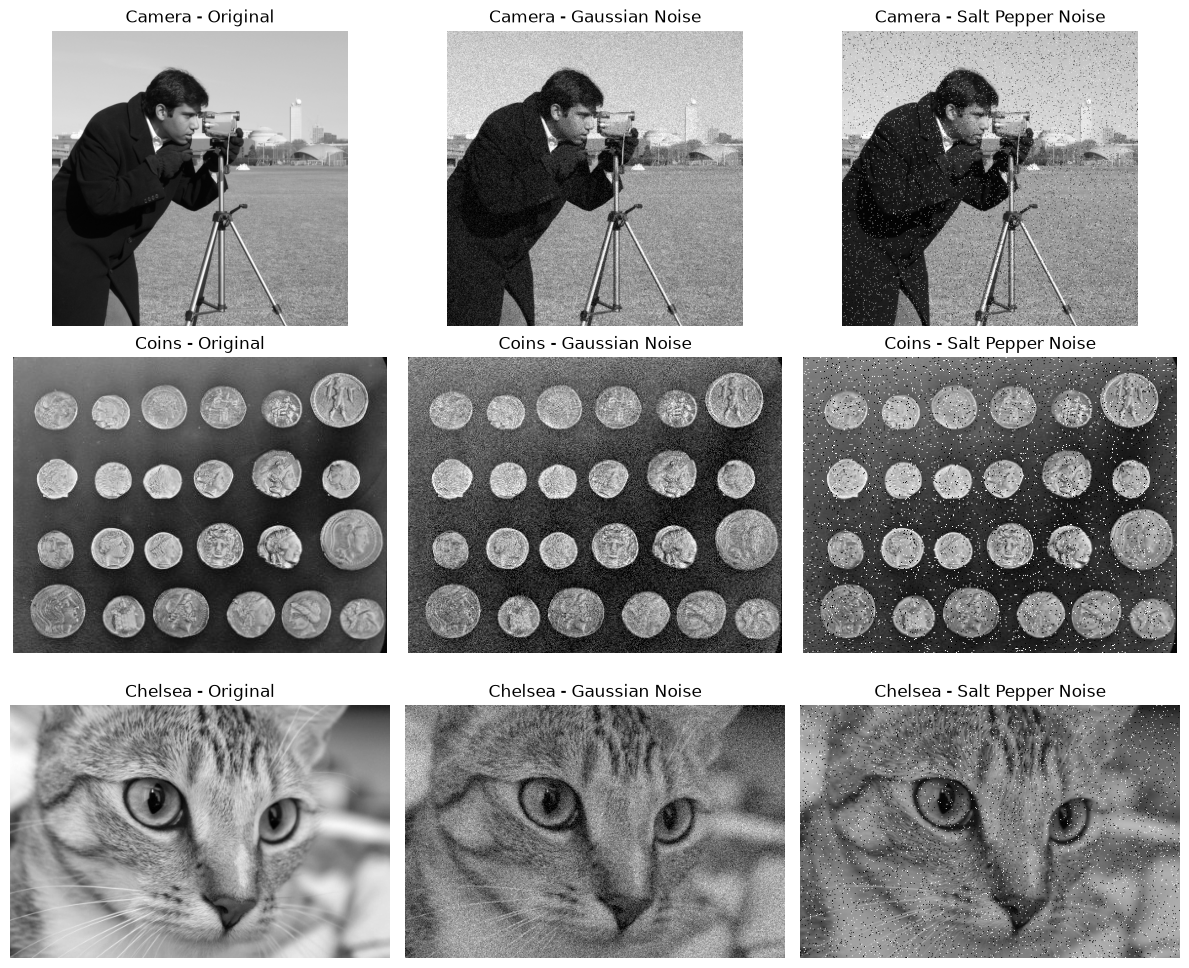

In [21]:
plt.figure(figsize=(12, 10))

for row, (name, img) in enumerate(images.items()):

    plt.subplot(3, 3, row * 3 + 1)
    plt.imshow(img, cmap="gray")
    plt.title(name + " - Original")
    plt.axis("off")

    plt.subplot(3, 3, row * 3 + 2)
    plt.imshow(
        noisy_images[name + " - Gaussian"],
        cmap="gray"
    )
    plt.title(name + " - Gaussian Noise")
    plt.axis("off")

    plt.subplot(3, 3, row * 3 + 3)
    plt.imshow(
        noisy_images[name + " - Salt Pepper"],
        cmap="gray"
    )
    plt.title(name + " - Salt Pepper Noise")
    plt.axis("off")

plt.tight_layout()
plt.show()

7. Implementing Mean, Gaussian and Median Filters
Three types of filters are implemented:

Mean Filter: Calculates the average of neighbouring pixels.

Gaussian Filter: Uses Gaussian weights to give more importance to central pixels.

Median Filter: Sorts neighbouring pixel values and selects the middle value.

The kernel sizes used are 3×3, 5×5 and 7×7.

In [22]:
def to_uint8(img):

    return np.clip(
        np.round(img), 0, 255
    ).astype(np.uint8)


def mean_filter(img, size=3):

    if size not in [3, 5, 7]:
        raise ValueError("Kernel size must be 3, 5 or 7.")

    kernel = np.ones(
        (size, size), dtype=np.float64
    )

    kernel = kernel / (size * size)

    print("Mean Kernel Sum:", kernel.sum())

    result = conv2d_loop(img, kernel)

    return to_uint8(result)


def gaussian_filter(img, size=3):

    if size not in [3, 5, 7]:
        raise ValueError("Kernel size must be 3, 5 or 7.")

    gaussian_1d = cv2.getGaussianKernel(size, 0)

    kernel = gaussian_1d @ gaussian_1d.T

    print("Gaussian Kernel Sum:", kernel.sum())

    result = cv2.GaussianBlur(
        img,
        (size, size),
        0,
        borderType=cv2.BORDER_REFLECT_101
    )

    return to_uint8(result)


def median_filter(img, size=3):

    if size not in [3, 5, 7]:
        raise ValueError("Kernel size must be 3, 5 or 7.")

    pad = size // 2

    padded = np.pad(
        img,
        ((pad, pad), (pad, pad)),
        mode="reflect"
    )

    filtered = cv2.medianBlur(padded, size)

    result = filtered[
        pad:-pad,
        pad:-pad
    ]

    return to_uint8(result)

8. Testing the Filters
The three filters are applied to the Camera image using a 3×3 kernel.

In [23]:
test_image = images["Camera"]

mean_result = mean_filter(test_image, 3)

gaussian_result = gaussian_filter(test_image, 3)

median_result = median_filter(test_image, 3)

print("Mean Filter:", mean_result.shape, mean_result.dtype)
print("Gaussian Filter:", gaussian_result.shape, gaussian_result.dtype)
print("Median Filter:", median_result.shape, median_result.dtype)

Mean Kernel Sum: 1.0
Gaussian Kernel Sum: 1.0
Mean Filter: (512, 512) uint8
Gaussian Filter: (512, 512) uint8
Median Filter: (512, 512) uint8


9. Comparing Custom Mean Filter with OpenCV
The custom Mean filter is compared with OpenCV's cv2.blur() function.

Both outputs should agree within rounding.

In [25]:
img = images["Camera"]

kernel = np.ones((3, 3), dtype=np.float64) / 9

custom_mean = conv2d_loop(img, kernel)

opencv_mean = cv2.blur(
    img,
    (3, 3),
    borderType=cv2.BORDER_REFLECT_101
)

custom_mean_uint8 = to_uint8(custom_mean)

mean_difference = np.max(
    np.abs(
        custom_mean_uint8.astype(np.int16) -
        opencv_mean.astype(np.int16)
    )
)

print("Largest Difference:", mean_difference)

print(
    "Results Agree Within Rounding:",
    mean_difference <= 1
)

Largest Difference: 0
Results Agree Within Rounding: True


10. Applying Filters to Every Noisy Image
Mean, Gaussian and Median filters are applied to all noisy images using a 3×3 kernel.

In [26]:
filtered_images = {}

for name, img in noisy_images.items():

    filtered_images[name] = {}

    filtered_images[name]["Mean"] = mean_filter(img, 3)

    filtered_images[name]["Gaussian"] = gaussian_filter(img, 3)

    filtered_images[name]["Median"] = median_filter(img, 3)

print("All noisy images filtered successfully!")

Mean Kernel Sum: 1.0
Gaussian Kernel Sum: 1.0
Mean Kernel Sum: 1.0
Gaussian Kernel Sum: 1.0
Mean Kernel Sum: 1.0
Gaussian Kernel Sum: 1.0
Mean Kernel Sum: 1.0
Gaussian Kernel Sum: 1.0
Mean Kernel Sum: 1.0
Gaussian Kernel Sum: 1.0
Mean Kernel Sum: 1.0
Gaussian Kernel Sum: 1.0
All noisy images filtered successfully!


11. Displaying Filter Comparison
The noisy images are compared with their Mean, Gaussian and Median filtered results.

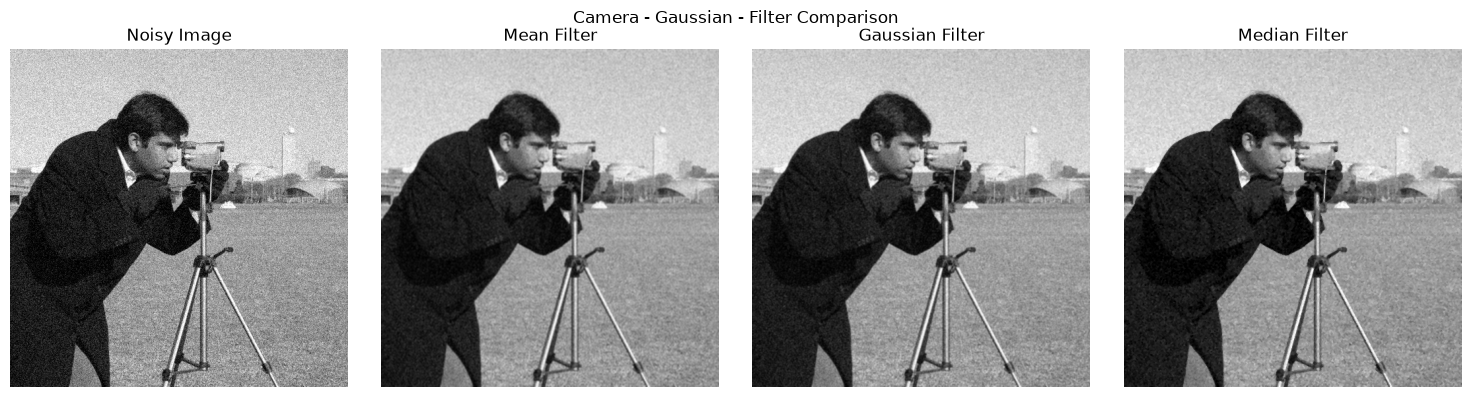

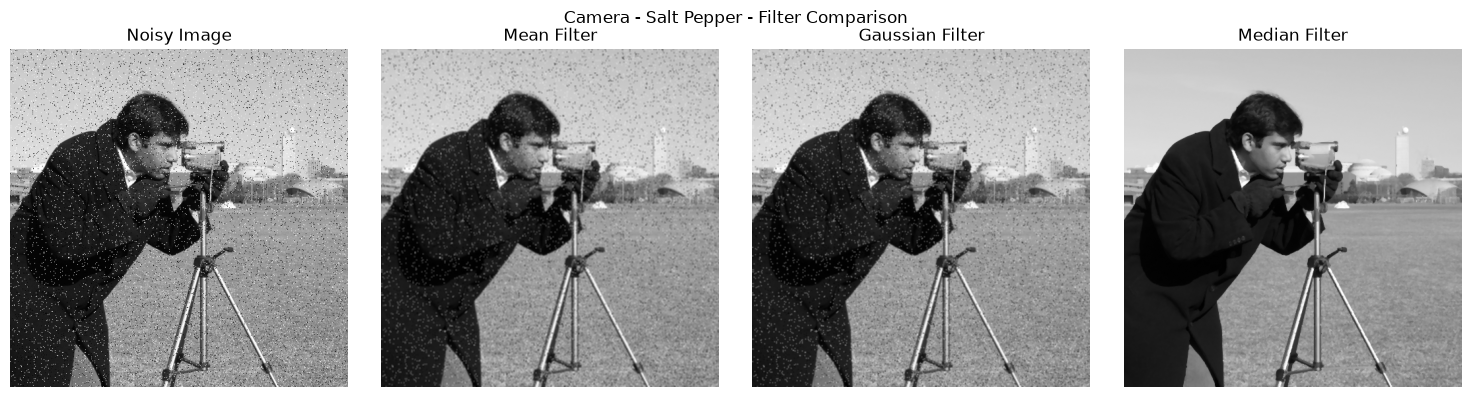

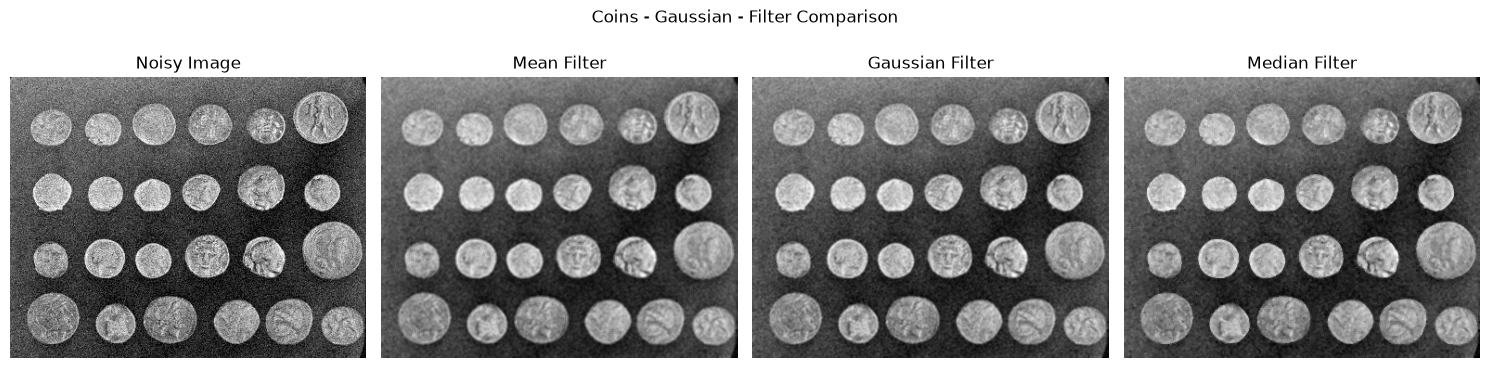

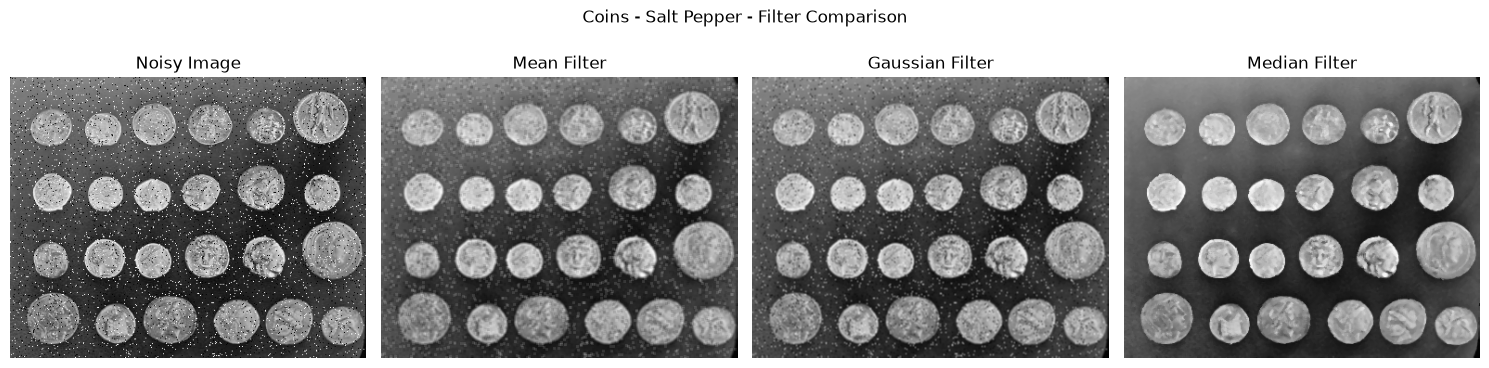

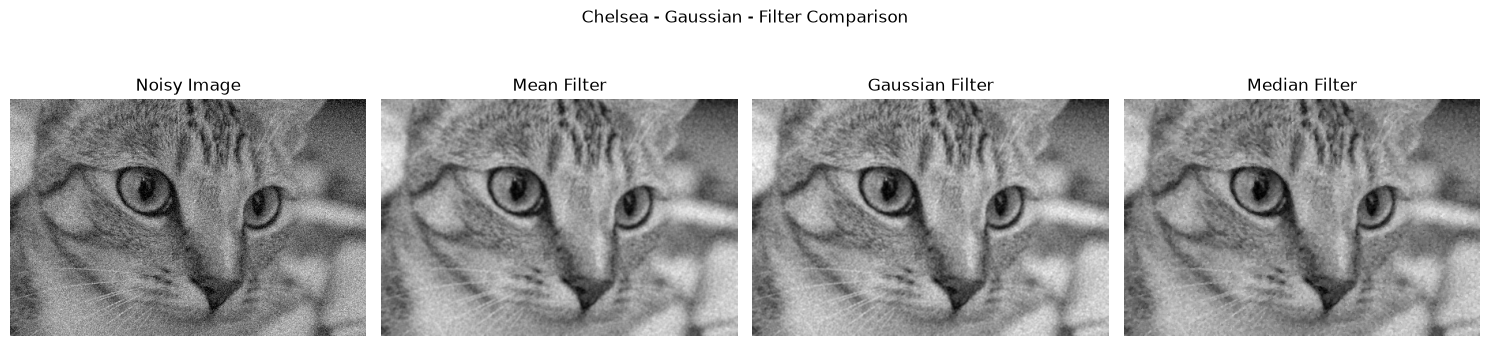

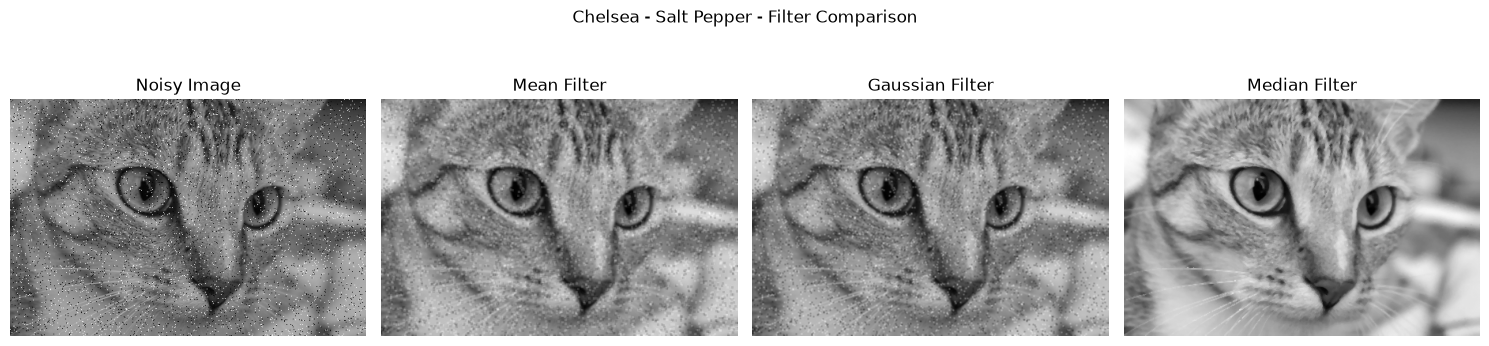

In [27]:
for name, noisy_img in noisy_images.items():

    plt.figure(figsize=(15, 4))

    plt.subplot(1, 4, 1)
    plt.imshow(noisy_img, cmap="gray")
    plt.title("Noisy Image")
    plt.axis("off")

    for i, filter_name in enumerate(
        ["Mean", "Gaussian", "Median"]
    ):

        plt.subplot(1, 4, i + 2)

        plt.imshow(
            filtered_images[name][filter_name],
            cmap="gray"
        )

        plt.title(filter_name + " Filter")
        plt.axis("off")

    plt.suptitle(name + " - Filter Comparison")

    plt.tight_layout()
    plt.show()

12. Comparing Different Kernel Sizes
The Mean, Gaussian and Median filters are compared using 3×3, 5×5 and 7×7 kernel sizes.

The Coins image with Salt-and-Pepper noise is selected for this comparison.

Mean Kernel Sum: 1.0
Mean Kernel Sum: 1.0
Mean Kernel Sum: 0.9999999999999999
Gaussian Kernel Sum: 1.0
Gaussian Kernel Sum: 1.0
Gaussian Kernel Sum: 1.0


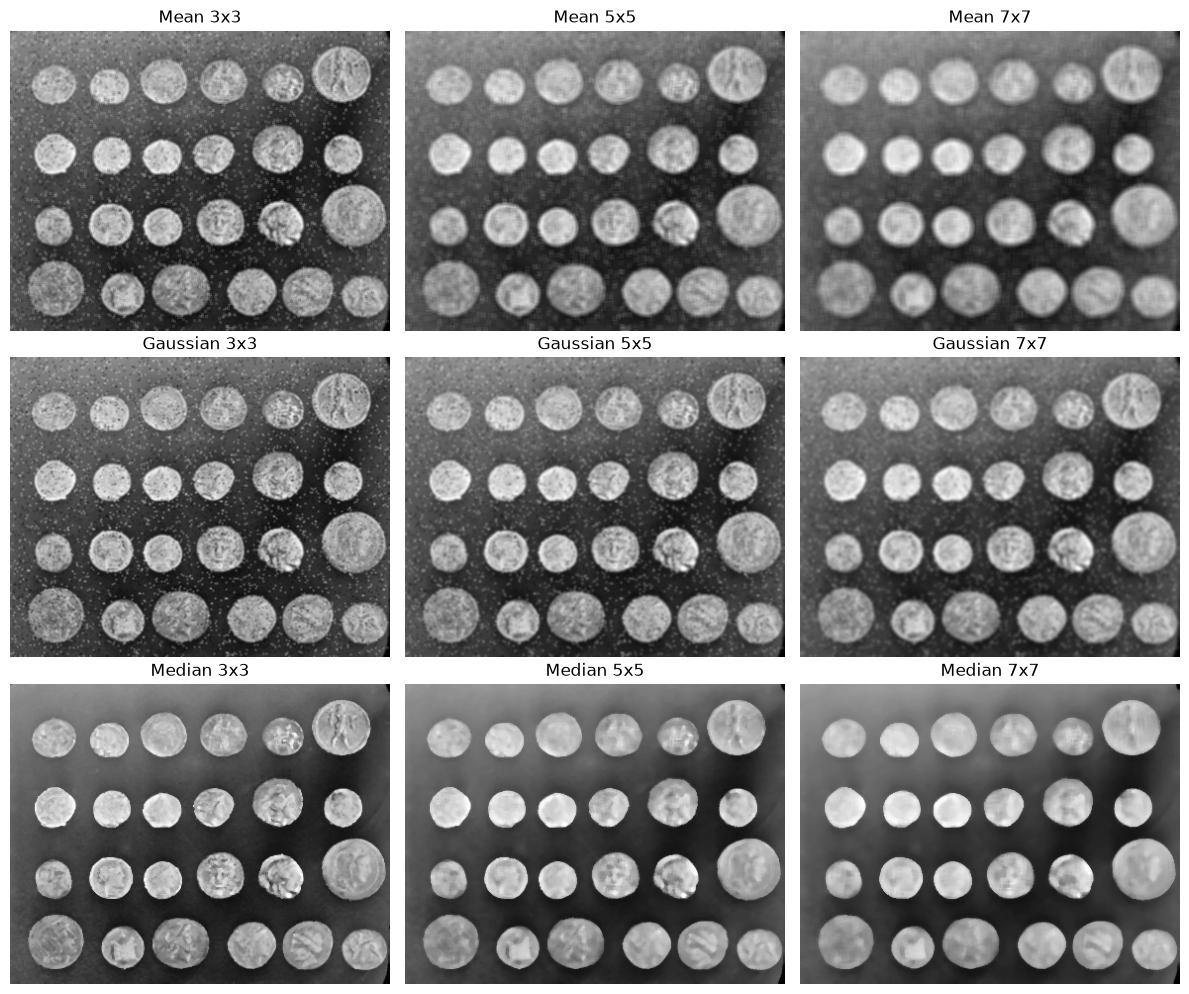

In [28]:
selected_image = noisy_images["Coins - Salt Pepper"]

kernel_sizes = [3, 5, 7]

plt.figure(figsize=(12, 10))

for row, (filter_name, filter_function) in enumerate([
    ("Mean", mean_filter),
    ("Gaussian", gaussian_filter),
    ("Median", median_filter)
]):

    for col, size in enumerate(kernel_sizes):

        result = filter_function(selected_image, size)

        plt.subplot(3, 3, row * 3 + col + 1)

        plt.imshow(result, cmap="gray")

        plt.title(f"{filter_name} {size}x{size}")

        plt.axis("off")

plt.tight_layout()
plt.show()

13. Rule Compliance Checks
The following rules are checked:
- R1: Every filter returns an image with the same size as the input.
- R2: Calculations use float64 and final outputs use uint8.
- R3: Smoothing kernel weights sum to 1.
- R4: Kernel sizes must be odd: 3, 5 or 7.

In [29]:
original = images["Camera"]

for filter_name, filter_function in [
    ("Mean", mean_filter),
    ("Gaussian", gaussian_filter),
    ("Median", median_filter)
]:

    for size in [3, 5, 7]:

        result = filter_function(original, size)

        print("\nFilter:", filter_name)
        print("Kernel Size:", size)
        print("Data Type:", result.dtype)
        print("Shape:", result.shape)
        print("Minimum:", result.min())
        print("Maximum:", result.max())

        print("Same Shape:", result.shape == original.shape)
        print("Uint8:", result.dtype == np.uint8)

        print(
            "Range Valid:",
            result.min() >= 0 and result.max() <= 255
        )

Mean Kernel Sum: 1.0

Filter: Mean
Kernel Size: 3
Data Type: uint8
Shape: (512, 512)
Minimum: 2
Maximum: 255
Same Shape: True
Uint8: True
Range Valid: True
Mean Kernel Sum: 1.0

Filter: Mean
Kernel Size: 5
Data Type: uint8
Shape: (512, 512)
Minimum: 3
Maximum: 253
Same Shape: True
Uint8: True
Range Valid: True
Mean Kernel Sum: 0.9999999999999999

Filter: Mean
Kernel Size: 7
Data Type: uint8
Shape: (512, 512)
Minimum: 3
Maximum: 250
Same Shape: True
Uint8: True
Range Valid: True
Gaussian Kernel Sum: 1.0

Filter: Gaussian
Kernel Size: 3
Data Type: uint8
Shape: (512, 512)
Minimum: 2
Maximum: 255
Same Shape: True
Uint8: True
Range Valid: True
Gaussian Kernel Sum: 1.0

Filter: Gaussian
Kernel Size: 5
Data Type: uint8
Shape: (512, 512)
Minimum: 3
Maximum: 255
Same Shape: True
Uint8: True
Range Valid: True
Gaussian Kernel Sum: 1.0

Filter: Gaussian
Kernel Size: 7
Data Type: uint8
Shape: (512, 512)
Minimum: 3
Maximum: 253
Same Shape: True
Uint8: True
Range Valid: True

Filter: Median
Kernel Si

In [30]:
try:

    cv2.medianBlur(images["Camera"], 4)

except cv2.error:

    print("Even kernel size 4 is rejected successfully.")

Even kernel size 4 is rejected successfully.


14. Dry-Run Exercises
Exercise 1 – Spike Response
Given 3×3 neighbourhood:
\[
\begin{bmatrix}
40&40&40\\
40&255&40\\
40&40&40
\end{bmatrix}
\]
Calculate the centre output using Mean, Gaussian and Median filters.

In [31]:
spike = np.array([
    [40, 40, 40],
    [40, 255, 40],
    [40, 40, 40]
], dtype=np.float64)

mean_kernel = np.ones((3, 3)) / 9

gaussian_kernel = np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
], dtype=np.float64) / 16

mean_value = np.sum(spike * mean_kernel)

gaussian_value = np.sum(spike * gaussian_kernel)

median_value = np.median(spike)

print("Mean Filter:", mean_value)

print("Gaussian Filter:", gaussian_value)

print("Median Filter:", median_value)

Mean Filter: 63.88888888888889
Gaussian Filter: 93.75
Median Filter: 40.0


Exercise 1 – Hand Calculations
1. Mean Filter
\[
\frac{8(40)+255}{9}
\]
\[
=\frac{575}{9}
\]
\[
\boxed{63.89}
\]
2. Gaussian Filter
\[
\frac{
40+80+40+80+1020+80+40+80+40
}{16}
\]
\[
=\frac{1500}{16}
\]
\[
\boxed{93.75}
\]
3. Median Filter

Sorted values:
\[
40,40,40,40,40,40,40,40,255
\]
Middle value:
\[
\boxed{40}
\]
Final Results:
Filter	Centre Output
Mean	63.89
Gaussian	93.75
Median	40


Exercise 2 – Reflect Padding at a Corner
Given image:
\[
\begin{bmatrix}
10&20&30\\
40&50&60\\
70&80&90
\end{bmatrix}
\]
Calculate the 3×3 Mean-filtered value at the top-left pixel (0,0) using reflect padding.

In [32]:
small_image = np.array([
    [10, 20, 30],
    [40, 50, 60],
    [70, 80, 90]
])

padded_image = np.pad(
    small_image,
    1,
    mode="reflect"
)

neighbourhood = padded_image[:3, :3]

mean_value = np.mean(neighbourhood)

print("Padded Neighbourhood:")

print(neighbourhood)

print("Mean Value:", mean_value)

Padded Neighbourhood:
[[50 40 50]
 [20 10 20]
 [50 40 50]]
Mean Value: 36.666666666666664


Exercise 2 – Hand Calculations
The reflected 3×3 neighbourhood is:
\[
\begin{bmatrix}
50&40&50\\
20&10&20\\
50&40&50
\end{bmatrix}
\]
Mean calculation:
\[
\frac{50+40+50+20+10+20+50+40+50}{9}
\]
\[
=\frac{330}{9}
\]
\[
\boxed{36.67}
\]
Final Answer: 36.67

15. Observations and Comparisons


1- Which filter looks best on Gaussian noise, and which looks worst?
The Gaussian filter generally performs best on Gaussian noise because it reduces random variations and produces a smoother image.
The Mean filter can cause more blurring and loss of fine details.
In the Camera image, the smooth background region shows the reduction of Gaussian noise after filtering.


2-Which filter looks best on Salt-and-Pepper noise, and why do the other two fail?
The Median filter performs best on Salt-and-Pepper noise because it removes extreme black and white pixels while preserving important image details.
Mean and Gaussian filters are less effective because they average noisy pixels with their neighbouring pixels, which can spread the effect of noise.
In the Coins image, the black and white spots can be compared before and after Median filtering.


3- How do Mean and Gaussian filters compare on a sharp edge?
Both filters smooth sharp edges.
The Mean filter gives equal importance to all neighbouring pixels, while the Gaussian filter gives more importance to central pixels.
The Gaussian filter generally produces smoother results.
The boundaries of the coins show the difference between both filters.



4- What happens to fine details at 7×7?
A 7×7 kernel produces stronger smoothing because it considers more neighbouring pixels.
Fine details become less visible, and edges become blurrier.
The small details and boundaries in the Coins image can be observed in the kernel-size comparison grid.



5-Why must the kernel size be odd?
The kernel size must be odd so that there is one central pixel.
For example, a 3×3 kernel has one centre pixel, whereas a 4×4 kernel does not have a single central pixel.
This allows the filter to be positioned correctly around each output pixel.

16. Viva Preparation

    
Q1. What is a kernel?
A kernel is a small matrix of numbers used to process an image. It moves over the image and performs calculations on neighbouring pixels to produce a filtered image.


Q2. Why does the median remove a 255 spike but the mean does not?
The median selects the middle value after sorting neighbouring pixels. Therefore, one extreme value like 255 does not significantly affect the result. The mean calculates the average, so an extreme value can increase the output.


Q3. Why do Gaussian weights sum to 16, and why divide by it?
The Gaussian 3×3 kernel has weights whose total is 16. We divide by 16 to make the sum of all weights equal to 1 and maintain image brightness.


Q4. Why do we pad the border before filtering?
Padding provides neighbouring pixel values for boundary pixels and ensures that the output image has the same dimensions as the input image.


Q5. Which filter would you use for Salt-and-Pepper noise, and why?
I would use the Median filter because it removes extreme black and white pixels effectively while preserving image details.



17. Conclusion

In this lab task, two-dimensional convolution was implemented using Python and NumPy. Mean, Gaussian and Median filters were applied to Camera, Coins and Chelsea images.

Gaussian and Salt-and-Pepper noise were added to the images using a fixed random seed. Different kernel sizes, including 3×3, 5×5 and 7×7, were tested.

The results showed that Median filtering is effective for Salt-and-Pepper noise, while Gaussian filtering is useful for reducing Gaussian noise.

The custom convolution implementation was also verified against OpenCV.

This lab helped in understanding spatial filtering, convolution, noise reduction and image processing techniques.